# 5. Scalability and Performance Comparison

This section compares Pandas, Polars and PySpark using equivalent data-processing tasks on the same bank-quarter dataset.

The comparison focuses on execution time, data loading, filtering and aggregation performance.

## 5.1. Environment and Library Setup

In [1]:
# 5.1. Import Libraries

import sys
import time
import platform
from pathlib import Path

import pandas as pd
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Python version:", sys.version)
print("Platform:", platform.platform())
print("Pandas version:", pd.__version__)
print("Polars version:", pl.__version__)
print("NumPy version:", np.__version__)

Python version: 3.14.8 (tags/v3.14.8:8e6e75d, Sep 30 2026, 18:19:33) [MSC v.1944 64 bit (AMD64)]
Platform: Windows-11-10.0.26200-SP0
Pandas version: 3.1.1
Polars version: 2.1.0
NumPy version: 2.5.4


In [2]:
# Check PySpark availability

try:
    import pyspark
    from pyspark.sql import SparkSession
    from pyspark.sql import functions as F

    print("PySpark version:", pyspark.__version__)
    pyspark_available = True

except ImportError:
    print("PySpark is not installed.")
    pyspark_available = False

PySpark version: 4.3.0


## 5.2. Dataset Selection

The benchmark uses the processed bank-quarter feature dataset generated during the data preparation and feature engineering stages.

All processing frameworks should operate on equivalent records and perform equivalent operations to ensure a fair comparison.

In [3]:
# 5.2. Load Dataset Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

feature_path = (
    project_root
    / "data"
    / "processed"
    / "v3"
    / "bank_quarter_features_v3.parquet"
)

figure_dir = project_root / "reports" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

if not feature_path.exists():
    raise FileNotFoundError(
        f"Dataset not found: {feature_path}"
    )

print("Dataset:", feature_path)
print("File size (MB):", round(feature_path.stat().st_size / (1024**2), 2))

Dataset: c:\Users\ADMIN\OneDrive\BFT65B_Final_Project\data\processed\v3\bank_quarter_features_v3.parquet
File size (MB): 171.92


In [4]:
# 5.3. Inspect Dataset

benchmark_data = pl.read_parquet(feature_path)

print("Dataset shape:", benchmark_data.shape)
print("\nColumns:")
print(benchmark_data.columns)

print("\nData types:")
print(benchmark_data.schema)

Dataset shape: (1663876, 36)

Columns:
['NCLNLS', 'LNATRES', 'ROA', 'REPDTE', 'ASSET', 'RBC1AAJ', 'CERT', 'NETINC', 'EQ', 'DEP', 'ID', 'REPORT_DATE', 'REPORT_Q_INDEX', 'FIRST_FAILURE_DATE', 'FAILURE_Q_INDEX', 'FAILURE_LABEL', 'IS_MERGER_CENSORED', 'FINAL_LABEL', 'YEAR', 'QUARTER', 'PREV_NETINC_YTD', 'PREV_QUARTER', 'QUARTERLY_NETINC', 'LOG_ASSET', 'EQUITY_TO_ASSETS', 'DEPOSITS_TO_ASSETS', 'NEGATIVE_NCLNLS_FLAG', 'NEGATIVE_LNATRES_FLAG', 'NPL_TO_ASSETS', 'ALLOWANCE_TO_ASSETS', 'ASSET_QOQ_GROWTH', 'EQUITY_RATIO_CHANGE', 'ROA_CHANGE', 'NPL_RATIO_CHANGE', 'ALLOWANCE_RATIO_CHANGE', 'EXTREME_ASSET_GROWTH_FLAG']

Data types:
Schema({'NCLNLS': Float64, 'LNATRES': Float64, 'ROA': Float64, 'REPDTE': String, 'ASSET': Int64, 'RBC1AAJ': Float64, 'CERT': Int64, 'NETINC': Float64, 'EQ': Float64, 'DEP': Float64, 'ID': String, 'REPORT_DATE': Date, 'REPORT_Q_INDEX': Int32, 'FIRST_FAILURE_DATE': Date, 'FAILURE_Q_INDEX': Int32, 'FAILURE_LABEL': Int8, 'IS_MERGER_CENSORED': Boolean, 'FINAL_LABEL': Int8, 'YE

## 5.3. Benchmark Tasks

Three equivalent data-processing tasks are selected:

1. Data loading: read the bank-quarter Parquet dataset.
2. Filtering: retain observations with non-null final labels and valid reporting periods.
3. Aggregation: calculate the number of observations and the failure rate by year.

The same source dataset and equivalent logical operations are used across the available frameworks.

### 5.5.1. Pandas Benchmark

In [5]:
# Pandas - Data Loading

pandas_load_start = time.perf_counter()

pandas_data = pd.read_parquet(feature_path)

pandas_load_time = time.perf_counter() - pandas_load_start

print("Pandas shape:", pandas_data.shape)
print("Pandas loading time:", round(pandas_load_time, 4), "seconds")

Pandas shape: (1663876, 36)
Pandas loading time: 3.2192 seconds


In [6]:
# Pandas - Filtering

pandas_filter_start = time.perf_counter()

pandas_filtered = pandas_data[
    pandas_data["FINAL_LABEL"].notna()
].copy()

pandas_filter_time = time.perf_counter() - pandas_filter_start

print("Filtered shape:", pandas_filtered.shape)
print("Filtering time:", round(pandas_filter_time, 4), "seconds")

Filtered shape: (1608079, 36)
Filtering time: 1.4849 seconds


In [7]:
# Pandas - GroupBy Aggregation

pandas_agg_start = time.perf_counter()

pandas_aggregation = (
    pandas_filtered
    .groupby("YEAR", dropna=False)
    .agg(
        OBSERVATIONS=("FINAL_LABEL", "size"),
        FAILURES=("FINAL_LABEL", "sum")
    )
    .reset_index()
)

pandas_aggregation["FAILURE_RATE"] = (
    pandas_aggregation["FAILURES"]
    / pandas_aggregation["OBSERVATIONS"]
)

pandas_agg_time = time.perf_counter() - pandas_agg_start

print("Pandas aggregation time:", round(pandas_agg_time, 4), "seconds")
display(pandas_aggregation.head())

Pandas aggregation time: 0.2245 seconds


,YEAR,OBSERVATIONS,FAILURES,FAILURE_RATE
0,1984,70635,427.0,0.006045
1,1985,70770,562.0,0.007941
2,1986,70216,777.0,0.011066
3,1987,67831,834.0,0.012295
4,1988,65734,1864.0,0.028357


### 5.5.2. Polars Benchmark

In [8]:
# Polars - Data Loading

polars_load_start = time.perf_counter()

polars_data = pl.read_parquet(feature_path)

polars_load_time = time.perf_counter() - polars_load_start

print("Polars shape:", polars_data.shape)
print("Polars loading time:", round(polars_load_time, 4), "seconds")

Polars shape: (1663876, 36)
Polars loading time: 0.7632 seconds


In [9]:
# Polars - Filtering

polars_filter_start = time.perf_counter()

polars_filtered = polars_data.filter(
    pl.col("FINAL_LABEL").is_not_null()
)

polars_filter_time = time.perf_counter() - polars_filter_start

print("Filtered shape:", polars_filtered.shape)
print("Filtering time:", round(polars_filter_time, 4), "seconds")

Filtered shape: (1608079, 36)
Filtering time: 0.3754 seconds


In [10]:
# Polars - GroupBy Aggregation

polars_agg_start = time.perf_counter()

polars_aggregation = (
    polars_filtered
    .group_by("YEAR")
    .agg([
        pl.len().alias("OBSERVATIONS"),
        pl.col("FINAL_LABEL").sum().alias("FAILURES")
    ])
    .with_columns(
        (
            pl.col("FAILURES") / pl.col("OBSERVATIONS")
        ).alias("FAILURE_RATE")
    )
    .sort("YEAR")
)

polars_agg_time = time.perf_counter() - polars_agg_start

print("Polars aggregation time:", round(polars_agg_time, 4), "seconds")
display(polars_aggregation.head())

Polars aggregation time: 0.3202 seconds


YEAR,OBSERVATIONS,FAILURES,FAILURE_RATE
i32,u32,i64,f64
1984,70635,427,0.006045
1985,70770,562,0.007941
1986,70216,777,0.011066
1987,67831,834,0.012295
1988,65734,1864,0.028357


In [11]:
# Compare Pandas and Polars aggregation results

pandas_check = pandas_aggregation.sort_values("YEAR").reset_index(drop=True)

polars_check = (
    polars_aggregation
    .to_pandas()
    .sort_values("YEAR")
    .reset_index(drop=True)
)

print("Same number of rows:", len(pandas_check) == len(polars_check))

print(
    "Observation counts match:",
    np.array_equal(
        pandas_check["OBSERVATIONS"].to_numpy(),
        polars_check["OBSERVATIONS"].to_numpy()
    )
)

print(
    "Failure counts match:",
    np.array_equal(
        pandas_check["FAILURES"].to_numpy(),
        polars_check["FAILURES"].to_numpy()
    )
)

Same number of rows: True
Observation counts match: True
Failure counts match: True


### 5.5.3. PySpark Benchmark

PySpark is evaluated as a distributed data-processing framework. Its execution time is measured separately from Spark initialization to distinguish framework startup overhead from data-processing time.

In [28]:
import os
import sys
import time
import shutil
from pathlib import Path

# 1. Tìm Java/JDK mà không phụ thuộc vào một phiên bản thư mục cụ thể
java_candidates = []

# Ưu tiên JAVA_HOME đã có trong môi trường
configured_java_home = os.environ.get("JAVA_HOME")
if configured_java_home:
    java_candidates.append(Path(configured_java_home))

# Tìm Java từ PATH
java_executable = shutil.which("java")
if java_executable:
    java_path = Path(java_executable).resolve()
    java_candidates.append(java_path.parent.parent)

# Các vị trí JDK phổ biến trên Windows
java_candidates.extend([
    Path(r"C:\Program Files\Eclipse Adoptium"),
    Path(r"C:\Program Files\Java"),
    Path(r"C:\Program Files\Microsoft"),
])

java_home = None

for candidate in java_candidates:
    if not candidate.exists():
        continue

    # JAVA_HOME có thể trỏ thẳng tới JDK hoặc thư mục chứa các JDK
    possible_homes = [candidate]

    if candidate.is_dir():
        possible_homes.extend(
            path for path in candidate.iterdir()
            if path.is_dir() and ("jdk" in path.name.lower() or "temurin" in path.name.lower())
        )

    for home in possible_homes:
        java_exe = home / "bin" / "java.exe"
        if java_exe.is_file():
            java_home = home
            break

    if java_home is not None:
        break

if java_home is None:
    raise FileNotFoundError(
        "Không tìm thấy Java JDK. Hãy cài JDK 17 và đặt biến JAVA_HOME "
        "trỏ tới thư mục JDK, sau đó khởi động lại Jupyter."
    )

# 2. Cấu hình môi trường cho PySpark
os.environ["JAVA_HOME"] = str(java_home)

java_bin = str(java_home / "bin")
path_entries = os.environ.get("PATH", "").split(os.pathsep)

if java_bin not in path_entries:
    os.environ["PATH"] = java_bin + os.pathsep + os.environ.get("PATH", "")

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"

# 3. Xác định thư mục dự án
project_root = Path.cwd()

if project_root.name.lower() == "notebooks":
    project_root = project_root.parent

# Nếu notebook chạy từ vị trí khác, tìm thư mục có data/processed
if not (project_root / "data" / "processed").is_dir():
    for parent in Path.cwd().parents:
        if (parent / "data" / "processed").is_dir():
            project_root = parent
            break

feature_path = (
    project_root
    / "data"
    / "processed"
    / "v3"
    / "bank_quarter_features_v3.parquet"
)

if not feature_path.is_file():
    raise FileNotFoundError(f"Dataset not found: {feature_path}")

# 4. Hiển thị thông tin xác nhận
print("Python executable:", sys.executable)
print("Java home:", java_home)
print("Java exists:", (java_home / "bin" / "java.exe").is_file())
print("Feature dataset:", feature_path)
print("Dataset size (MB):", round(feature_path.stat().st_size / (1024 ** 2), 2))

Python executable: c:\Users\ADMIN\OneDrive\BFT65B_Final_Project\.venv\Scripts\python.exe
Java home: C:\Program Files\Eclipse Adoptium\jdk-17.0.21.9-hotspot
Java exists: True
Feature dataset: c:\Users\ADMIN\OneDrive\BFT65B_Final_Project\data\processed\v3\bank_quarter_features_v3.parquet
Dataset size (MB): 171.92


In [29]:
import subprocess
subprocess.run([str(java_home / "bin" / "java.exe"), "-version"], check=True)

CompletedProcess(args=['C:\\Program Files\\Eclipse Adoptium\\jdk-17.0.21.9-hotspot\\bin\\java.exe', '-version'], returncode=0)

In [13]:
from pyspark.sql import SparkSession

# Stop the previous Spark session
try:
    spark.stop()
except:
    pass

# Measure Spark initialization time
spark_init_start = time.perf_counter()

spark = (
    SparkSession.builder
    .appName("BFT65B_PySpark_Benchmark")
    .master("local[2]")
    .config("spark.driver.memory", "4g")
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.pyspark.python", sys.executable)
    .getOrCreate()
)

spark_init_time = time.perf_counter() - spark_init_start

print("Spark version:", spark.version)
print("Spark master:", spark.sparkContext.master)
print(f"Spark initialization time: {spark_init_time:.4f} seconds")

c:\Users\ADMIN\OneDrive\BFT65B_Final_Project\.venv\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Spark version: 4.3.0
Spark master: local[2]
Spark initialization time: 15.9440 seconds


In [14]:
from pyspark.sql import functions as F

# Start measuring data-processing time
pyspark_start = time.perf_counter()

# Read the Parquet dataset
spark_df = spark.read.parquet(str(feature_path))

# Filter observations with valid labels
spark_filtered = spark_df.filter(
    F.col("FINAL_LABEL").isNotNull()
)

# Group observations by year
pyspark_result = (
    spark_filtered
    .groupBy("YEAR")
    .agg(
        F.count("*").alias("TOTAL_OBSERVATIONS"),
        F.sum("FINAL_LABEL").alias("FAILURE_OBSERVATIONS")
    )
    .orderBy("YEAR")
)

# Execute Spark transformations and retrieve results
pyspark_output = pyspark_result.collect()

# Stop measuring
pyspark_processing_time = time.perf_counter() - pyspark_start

print("PySpark processing completed.")
print(f"Data-processing time: {pyspark_processing_time:.4f} seconds")
print("Number of years:", len(pyspark_output))

pyspark_result.show(10)

PySpark processing completed.
Data-processing time: 12.2679 seconds
Number of years: 42
+----+------------------+--------------------+
|YEAR|TOTAL_OBSERVATIONS|FAILURE_OBSERVATIONS|
+----+------------------+--------------------+
|1984|             70635|                 427|
|1985|             70770|                 562|
|1986|             70216|                 777|
|1987|             67831|                 834|
|1988|             65734|                1864|
|1989|             62948|                1578|
|1990|             60760|                1158|
|1991|             57950|                 777|
|1992|             54899|                 380|
|1993|             52079|                  85|
+----+------------------+--------------------+
only showing top 10 rows


In [15]:
pyspark_total_observations = sum(
    row["TOTAL_OBSERVATIONS"]
    for row in pyspark_output
)

pyspark_total_failures = sum(
    row["FAILURE_OBSERVATIONS"]
    for row in pyspark_output
)

print("Total observations:", pyspark_total_observations)
print("Total failure observations:", pyspark_total_failures)
print("Spark initialization time:", round(spark_init_time, 4), "seconds")
print("Spark processing time:", round(pyspark_processing_time, 4), "seconds")

Total observations: 1608079
Total failure observations: 10860
Spark initialization time: 15.944 seconds
Spark processing time: 12.2679 seconds


In [16]:
import pandas as pd

pyspark_benchmark_results = pd.DataFrame([
    {
        "FRAMEWORK": "PySpark",
        "INITIALIZATION_TIME": spark_init_time,
        "PROCESSING_TIME": pyspark_processing_time,
        "TOTAL_TIME": spark_init_time + pyspark_processing_time,
        "TOTAL_OBSERVATIONS": pyspark_total_observations,
        "FAILURE_OBSERVATIONS": pyspark_total_failures
    }
])

benchmark_dir = project_root / "reports"
benchmark_dir.mkdir(parents=True, exist_ok=True)

pyspark_benchmark_results.to_csv(
    benchmark_dir / "pyspark_benchmark_results.csv",
    index=False
)

display(pyspark_benchmark_results)

,FRAMEWORK,INITIALIZATION_TIME,PROCESSING_TIME,TOTAL_TIME,TOTAL_OBSERVATIONS,FAILURE_OBSERVATIONS
0,PySpark,15.943958,12.267934,28.211892,1608079,10860


In [17]:
from pathlib import Path

result_path = project_root / "reports" / "pyspark_benchmark_results.csv"

print("File exists:", result_path.exists())
print("File path:", result_path)

File exists: True
File path: c:\Users\ADMIN\OneDrive\BFT65B_Final_Project\reports\pyspark_benchmark_results.csv


**PySpark Benchmark Results**

PySpark 4.3.0 was executed in local mode using two worker threads. The measured SparkSession initialization time was approximately 15.94 seconds, while data processing required approximately 12.27 seconds. The total measured time was approximately 28.21 seconds.

The benchmark processed 1,608,079 observations with valid failure labels, including 10,860 failure observations. These counts were consistent with the prepared FDIC dataset, confirming that the filtering and aggregation operations were performed correctly.

The processing stage included reading the Parquet dataset, filtering records with non-null labels, grouping observations by year, and collecting the aggregated results. The initialization measurement represents SparkSession creation within the existing Python process and may not capture the full cold-start overhead of a new Spark runtime.

Since Spark was executed in local mode on a single machine, the results should be interpreted as local processing performance rather than distributed-cluster performance. The reported timings represent a single benchmark run and may vary across runs.

### 5.6. Performance Comparison

The benchmark results indicate that Polars achieved the lowest measured total time among the three frameworks. Its total time across loading, filtering, and aggregation was approximately 1.46 seconds, compared with 4.93 seconds for Pandas.

PySpark required approximately 12.27 seconds for processing and 15.94 seconds for SparkSession initialization, resulting in a measured total of approximately 28.21 seconds.

All three frameworks produced the same results: 1,608,079 observations and 10,860 failure observations. This agreement supports the consistency of the aggregation results across the frameworks.

These results suggest that Polars was particularly efficient for the tested analytical workload. However, the comparison should be interpreted cautiously because the timing boundaries differ: Pandas and Polars were measured by individual processing stages, whereas PySpark's processing measurement included reading, filtering, aggregation, and collecting the results. Furthermore, Spark was executed in local mode rather than on a distributed cluster.

The benchmark represents a single measured run, and the results may vary across repeated runs. Therefore, the findings reflect the performance of these frameworks under the specific local experimental environment and workload, rather than a universal ranking of their performance.

In [24]:
import pandas as pd
import numpy as np

# Calculate total time from the measurements collected above.
pandas_total_time = (
    pandas_load_time
    + pandas_filter_time
    + pandas_agg_time
)

polars_total_time = (
    polars_load_time
    + polars_filter_time
    + polars_agg_time
)

pyspark_total_time = (
    spark_init_time
    + pyspark_processing_time
)

# Verify that all frameworks processed equivalent results.
pandas_total_observations = int(
    pandas_aggregation["OBSERVATIONS"].sum()
)
pandas_total_failures = int(
    pandas_aggregation["FAILURES"].sum()
)

polars_total_observations = int(
    polars_aggregation["OBSERVATIONS"].sum()
)
polars_total_failures = int(
    polars_aggregation["FAILURES"].sum()
)

assert pandas_total_observations == polars_total_observations, (
    "Pandas and Polars observation counts do not match."
)
assert pandas_total_failures == polars_total_failures, (
    "Pandas and Polars failure counts do not match."
)

assert pandas_total_observations == pyspark_total_observations, (
    "Pandas and PySpark observation counts do not match."
)
assert pandas_total_failures == pyspark_total_failures, (
    "Pandas and PySpark failure counts do not match."
)

comparison_results = pd.DataFrame([
    {
        "FRAMEWORK": "Pandas",
        "LOADING_TIME": pandas_load_time,
        "FILTERING_TIME": pandas_filter_time,
        "AGGREGATION_TIME": pandas_agg_time,
        "INITIALIZATION_TIME": 0.0,
        "PROCESSING_TIME": pandas_total_time,
        "TOTAL_TIME": pandas_total_time,
        "TOTAL_OBSERVATIONS": pandas_total_observations,
        "FAILURE_OBSERVATIONS": pandas_total_failures,
    },
    {
        "FRAMEWORK": "Polars",
        "LOADING_TIME": polars_load_time,
        "FILTERING_TIME": polars_filter_time,
        "AGGREGATION_TIME": polars_agg_time,
        "INITIALIZATION_TIME": 0.0,
        "PROCESSING_TIME": polars_total_time,
        "TOTAL_TIME": polars_total_time,
        "TOTAL_OBSERVATIONS": polars_total_observations,
        "FAILURE_OBSERVATIONS": polars_total_failures,
    },
    {
        "FRAMEWORK": "PySpark",
        "LOADING_TIME": np.nan,
        "FILTERING_TIME": np.nan,
        "AGGREGATION_TIME": np.nan,
        "INITIALIZATION_TIME": spark_init_time,
        "PROCESSING_TIME": pyspark_processing_time,
        "TOTAL_TIME": pyspark_total_time,
        "TOTAL_OBSERVATIONS": pyspark_total_observations,
        "FAILURE_OBSERVATIONS": pyspark_total_failures,
    },
])

display(comparison_results.round(4))

benchmark_dir = project_root / "reports"
benchmark_dir.mkdir(parents=True, exist_ok=True)

comparison_results.to_csv(
    benchmark_dir / "framework_comparison.csv",
    index=False,
)

print("Framework result counts match.")
print("Saved:", benchmark_dir / "framework_comparison.csv")

,FRAMEWORK,LOADING_TIME,FILTERING_TIME,AGGREGATION_TIME,INITIALIZATION_TIME,PROCESSING_TIME,TOTAL_TIME,TOTAL_OBSERVATIONS,FAILURE_OBSERVATIONS
0,Pandas,3.2192,1.4849,0.2245,0.000,4.9286,4.9286,1608079,10860
1,Polars,0.7632,0.3754,0.3202,0.000,1.4589,1.4589,1608079,10860
2,PySpark,NaN,NaN,NaN,15.944,12.2679,28.2119,1608079,10860


Framework result counts match.
Saved: c:\Users\ADMIN\OneDrive\BFT65B_Final_Project\reports\framework_comparison.csv


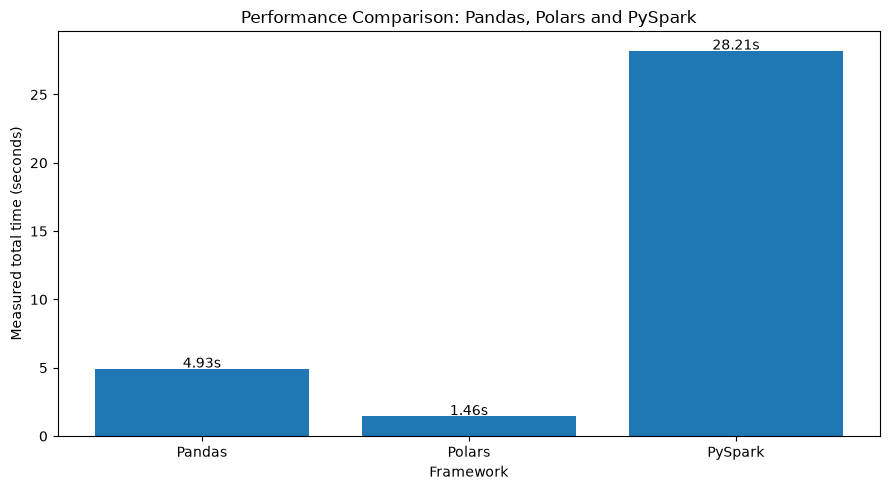

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_results["FRAMEWORK"],
    comparison_results["TOTAL_TIME"]
)

plt.ylabel("Measured total time (seconds)")
plt.xlabel("Framework")
plt.title("Performance Comparison: Pandas, Polars and PySpark")

for i, value in enumerate(comparison_results["TOTAL_TIME"]):
    plt.text(i, value + 0.08, f"{value:.2f}s", ha="center")

plt.tight_layout()

plt.savefig(
    figure_dir / "framework_total_time_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [26]:
# Phân tích kế hoạch thực thi của Spark cho phép tổng hợp dùng trong benchmark
from pyspark.sql import functions as F

spark_explain_query = (
    spark_df
    .filter(F.col("FINAL_LABEL").isNotNull())
    .groupBy("YEAR")
    .agg(
        F.count("*").alias("TOTAL_OBSERVATIONS"),
        F.sum("FINAL_LABEL").alias("FAILURE_OBSERVATIONS")
    )
)

print("=== SPARK EXECUTION PLAN (EXPLAIN FORMATTED) ===")
spark_explain_query.explain(mode="formatted")

=== SPARK EXECUTION PLAN (EXPLAIN FORMATTED) ===
== Physical Plan ==
AdaptiveSparkPlan (6)
+- HashAggregate (5)
   +- Exchange (4)
      +- HashAggregate (3)
         +- Filter (2)
            +- Scan parquet  (1)


(1) Scan parquet 
Output [2]: [FINAL_LABEL#17, YEAR#18]
Batched: true
Location: InMemoryFileIndex [file:/c:/Users/ADMIN/OneDrive/BFT65B_Final_Project/data/processed/v3/bank_quarter_features_v3.parquet]
PushedFilters: [IsNotNull(FINAL_LABEL)]
ReadSchema: struct<FINAL_LABEL:tinyint,YEAR:int>

(2) Filter
Input [2]: [FINAL_LABEL#17, YEAR#18]
Condition : isnotnull(FINAL_LABEL#17)

(3) HashAggregate
Input [2]: [FINAL_LABEL#17, YEAR#18]
Keys [1]: [YEAR#18]
Functions [2]: [partial_count(1), partial_sum(FINAL_LABEL#17)]
Aggregate Attributes [2]: [count#183L, sum#184L]
Results [3]: [YEAR#18, count#185L, sum#186L]

(4) Exchange
Input [3]: [YEAR#18, count#185L, sum#186L]
Arguments: hashpartitioning(YEAR#18, 200), ENSURE_REQUIREMENTS, [plan_id=205]

(5) HashAggregate
Input [3]: [YEAR#18

In [30]:
import polars as pl

polars_lazy_query = (
    pl.scan_parquet(feature_path)
    .filter(pl.col("FINAL_LABEL").is_not_null())
    .group_by("YEAR")
    .agg([
        pl.len().alias("TOTAL_OBSERVATIONS"),
        pl.col("FINAL_LABEL").sum().alias("FAILURE_OBSERVATIONS"),
    ])
)

print("=== POLARS LAZYFRAME EXECUTION PLAN ===")
print(polars_lazy_query.explain())

=== POLARS LAZYFRAME EXECUTION PLAN ===
AGGREGATE[maintain_order: false]
  [len().alias("TOTAL_OBSERVATIONS"), col("FINAL_LABEL").sum().alias("FAILURE_OBSERVATIONS")] BY [col("YEAR")]
  FROM
  Parquet SCAN [c:/Users/ADMIN/OneDrive/BFT65B_Final_Project/data/processed/v3/bank_quarter_features_v3.parquet]
  PROJECT 2/36 COLUMNS
  SELECTION: col("FINAL_LABEL").is_not_null()
  ESTIMATED ROWS: 1663876


In [27]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

# 1. Dùng project_root đã xác định ở đầu notebook
ROOT = Path(project_root).resolve()

if not ROOT.exists():
    raise FileNotFoundError(f"Project root không tồn tại: {ROOT}")

# 2. Lưu ZIP bên ngoài thư mục dự án để tránh tự đưa ZIP vào ZIP
OUTPUT = ROOT.parent / "BFT65B_Project_Audit.zip"

# 3. Các thư mục cần đóng gói
INCLUDE_DIRS = [
    "notebooks",
    "reports",
    "src",
    "scripts",
]

# 4. Các file quan trọng ở thư mục gốc
INCLUDE_FILES = [
    "README.md",
    "requirements.txt",
    ".gitignore",
]

# 5. Những thành phần không đưa vào ZIP
EXCLUDED_DIRS = {
    ".venv",
    ".git",
    "__pycache__",
    ".ipynb_checkpoints",
    ".pytest_cache",
    ".mypy_cache",
    "node_modules",
}

EXCLUDED_SUFFIXES = {".pyc", ".pyo", ".log"}

files_to_add = []

# Thu thập file trong các thư mục được chỉ định
for folder in INCLUDE_DIRS:
    folder_path = ROOT / folder

    if not folder_path.exists():
        print(f"Bỏ qua thư mục không tồn tại: {folder_path}")
        continue

    for path in folder_path.rglob("*"):
        if not path.is_file():
            continue

        relative_path = path.relative_to(ROOT)

        if any(part in EXCLUDED_DIRS for part in relative_path.parts):
            continue

        if path.suffix.lower() in EXCLUDED_SUFFIXES:
            continue

        files_to_add.append(path)

# Thu thập các file được chỉ định ở thư mục gốc
for filename in INCLUDE_FILES:
    path = ROOT / filename

    if path.is_file():
        files_to_add.append(path)

# Loại bỏ file trùng và sắp xếp danh sách
files_to_add = sorted(set(files_to_add))

if not files_to_add:
    raise RuntimeError("Không tìm thấy file nào để đóng gói. Kiểm tra ROOT và các thư mục đầu vào.")

# Tạo ZIP
with ZipFile(OUTPUT, "w", ZIP_DEFLATED) as zip_file:
    for path in files_to_add:
        zip_file.write(path, path.relative_to(ROOT))

print("ĐÃ TẠO GÓI AUDIT!")
print("Đường dẫn:", OUTPUT)
print("Số file:", len(files_to_add))
print("Dung lượng (MB):", round(OUTPUT.stat().st_size / (1024 ** 2), 2))

print("\nDANH SÁCH FILE:")
for path in files_to_add:
    print("-", path.relative_to(ROOT))

Bỏ qua thư mục không tồn tại: C:\Users\ADMIN\OneDrive\BFT65B_Final_Project\scripts
ĐÃ TẠO GÓI AUDIT!
Đường dẫn: C:\Users\ADMIN\OneDrive\BFT65B_Project_Audit.zip
Số file: 92
Dung lượng (MB): 4.67

DANH SÁCH FILE:
- .gitignore
- notebooks\01_data_exploration.ipynb
- notebooks\02_data_preprocessing.ipynb
- notebooks\03_feature_engineering.ipynb
- notebooks\04_modeling.ipynb
- notebooks\05_scalability_comparison.ipynb
- notebooks\audit_artifacts.py
- notebooks\figures\build_dataset.py
- README.md
- reports\audit_artifacts_output.txt
- reports\feature_dictionary.csv
- reports\figures\03_correlation_heatmap_financial_features.png
- reports\figures\04_annual_failure_distribution.png
- reports\figures\annual_bank_failures.png
- reports\figures\annual_financial_trends.png
- reports\figures\annual_number_of_banks.png
- reports\figures\correlation_heatmap.png
- reports\figures\correlation_heatmap_financial_features.png
- reports\figures\financial_variables_boxplots.png
- reports\figures\financial